---
# Executed by scripts/export_gw_examples.py; the docs build shows the stored outputs.
execute:
  skip: true
---
# 4. A damped sinusoid in white noise

This page was generated from [`notebooks/gw/04_ringdown_damped_sinusoid.py`](https://github.com/Potatoasad/astroinfer/blob/main/notebooks/gw/04_ringdown_damped_sinusoid.py), a marimo notebook. Sliders and other controls are shown at their default values. To change them, run the notebook with `uv run marimo edit notebooks/gw/04_ringdown_damped_sinusoid.py`.

This notebook reimplements the introductory example of
[ringdown](https://github.com/maxisi/ringdown), the package of Isi and Farr for fitting
quasinormal modes to gravitational-wave data. The example, `single_damped_sinusoid.ipynb`
in ringdown's documentation, fits one damped sinusoid in white Gaussian noise. ringdown
writes its model directly in NumPyro. Here the signal, the noise and the prior are astroinfer
objects, and the NumPyro model that ties them together is a few lines of `ai.sample`.
Notebook 5 replaces the free frequency and damping rate with the Kerr spectrum of a remnant
black hole, and the white noise with the noise of the LIGO detectors.

The signal is a sum of damped sinusoids, one per mode $n$, starting at $t=0$:

$$
h(t) = \sum_n A_n e^{-\gamma_n t}\cos(2\pi f_n t - \phi_n)
     = \sum_n e^{-\gamma_n t}\left[a_{x,n}\cos(2\pi f_n t) + a_{y,n}\sin(2\pi f_n t)\right],
$$

with the *quadratures* $a_x = A\cos\phi$ and $a_y = A\sin\phi$. As in ringdown, we sample the
quadratures rather than the amplitude and phase, because the posterior of $(a_x, a_y)$ has
no boundary at $A=0$ and does not wrap around in $\phi$. Each data sample is the signal plus
independent noise, $d_k = h(t_k) + n_k$ with $n_k\sim\mathcal N(0,\sigma^2)$.

In [1]:
import sys
from pathlib import Path

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts" / "marimo_docs_shim.py").is_file())
sys.path[:0] = [str(ROOT / "notebooks/gw"), str(ROOT / "scripts")]

import marimo_docs_shim
marimo_docs_shim.set_notebook_dir(ROOT / "notebooks/gw")
sys.modules["marimo"] = marimo_docs_shim

# marimo shows a figure only when a cell returns it. Stop Jupyter from also showing every
# figure a cell creates, and close them once the cell has run.
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import flush_figures
get_ipython().run_line_magic("matplotlib", "inline")
try:
    get_ipython().events.unregister("post_execute", flush_figures)
except ValueError:
    pass
get_ipython().events.register("post_execute", lambda: plt.close("all"))

# Show astroinfer objects with their HTML display (as Jupyter does), not the short markdown one.
get_ipython().display_formatter.formatters["text/markdown"].enabled = False
# Open every object display, so readers see the contents without having to click.
import astroinfer.display
astroinfer.display.set_options(expanded=True)


In [2]:
import jax

jax.config.update("jax_enable_x64", True)

from dataclasses import dataclass

import astroinfer as ai
import jax.numpy as jnp
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
from astroinfer import MeasurementProcess, batched_method, parameter, parameter_dataclass
from numpyro.distributions import constraints

# The colors of tutorials/_style.py: posterior, prior, data and truth.
POSTERIOR, PRIOR, DATA, TRUTH = "#418FC5", "#eb6834", "#1baf7a", "#17243D"

## The parameter types

One set of parameters $\theta$ holds every mode, so each field has a core axis `"mode"`. The
amplitude and phase are methods of the type, computed from the quadratures. The data are one
strain value per time sample, a core axis `"time"`.

In [3]:
@parameter_dataclass(name="Damped sinusoids", latex=r"\theta")
class DampedSinusoids:
    f: float = parameter(name="Frequency [Hz]", latex="f", index=("mode",), index_latex=("n",),
                         support=constraints.positive)
    gamma: float = parameter(name="Damping rate [1/s]", latex=r"\gamma", index=("mode",),
                             index_latex=("n",), support=constraints.positive)
    ax: float = parameter(name="Cosine quadrature", latex="a_x", index=("mode",),
                          index_latex=("n",))
    ay: float = parameter(name="Sine quadrature", latex="a_y", index=("mode",),
                          index_latex=("n",))

    @batched_method
    def amplitude(self):
        return jnp.hypot(self.ax, self.ay)

    @batched_method
    def phase(self):
        return jnp.arctan2(self.ay, self.ax)

In [4]:
@parameter_dataclass(name="Strain", latex="d")
class Strain:
    h: float = parameter(name="Strain", latex="d", index=("time",), index_latex=("k",))

In [5]:
def damped_sinusoids(t, f, gamma, ax, ay):
    """The sum over modes of the damped sinusoids, on the times t."""
    phase = 2 * jnp.pi * f[:, None] * t
    decay = jnp.exp(-gamma[:, None] * t)
    return jnp.sum(decay * (ax[:, None] * jnp.cos(phase) + ay[:, None] * jnp.sin(phase)), axis=0)

## The measurement process

The measurement process $\mathcal L(d\mid\theta)$ evaluates the signal on the sample times and
adds white noise of standard deviation $\sigma$. As in every measurement process, we write
the law for one $\theta$ and one $d$; astroinfer batches it.

In [6]:
@dataclass(eq=False)
class WhiteNoise(MeasurementProcess):
    t: jax.Array
    sigma: float = 1.0

    display_name = "Damped sinusoids in white noise"
    parameter_type = DampedSinusoids
    data_type = Strain

    def signal(self, theta):
        return damped_sinusoids(self.t, theta.f, theta.gamma, theta.ax, theta.ay)

    def sample_single(self, theta, key):
        noise = self.sigma * jax.random.normal(key, self.t.shape)
        return Strain(h=self.signal(theta) + noise)

    def logpdf_single(self, d, theta):
        return jnp.sum(dist.Normal(self.signal(theta), self.sigma).log_prob(d.h))

    def _display_config(self):
        return {"samples": len(self.t), "sampling rate [Hz]": round(1 / float(self.t[1] - self.t[0])),
                "sigma": self.sigma}

## Simulated data

The settings are those of ringdown's example: a sampling rate of 8192 Hz, an analysis segment
of 0.03 s starting at $t_0 = 0$ (246 samples), unit noise, and one mode with $A=5$, $\phi=0$,
$f = 250$ Hz and $\gamma = 250\ \mathrm{s}^{-1}$, a damping time of 4 ms. ringdown simulates
4 s of data and then cuts out the segment; with white noise the samples outside the segment
do not enter the likelihood, so we simulate the segment alone.

In [7]:
fs, duration = 8192, 0.03
detector = WhiteNoise(t=jnp.arange(int(round(duration * fs))) / fs, sigma=1.0)
truth = DampedSinusoids(f=jnp.array([250.0]), gamma=jnp.array([250.0]),
                        ax=jnp.array([5.0]), ay=jnp.array([0.0]))
data = detector.sample(truth, key=12345)
mo.hstack([truth, detector, data], justify="start", gap=2, align="start")

DampedSinusoids(batch_shape=(), f=(1,), gamma=(1,), ax=(1,), ay=(1,))

samples,246
sampling rate [Hz],8192
sigma,1.0


Strain(batch_shape=(), h=(246,))

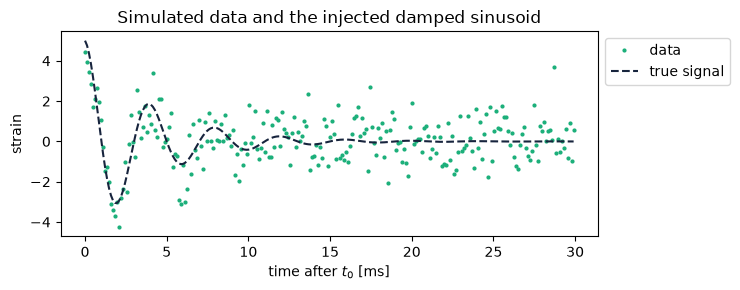

In [8]:
_t = 1e3 * np.asarray(detector.t)
_fig, _ax = plt.subplots(figsize=(7.5, 3.0))
_ax.plot(_t, np.asarray(data.h), ".", color=DATA, markersize=4, label="data")
_ax.plot(_t, np.asarray(detector.signal(truth)), color=TRUTH, linestyle="--", label="true signal")
_ax.set(xlabel="time after $t_0$ [ms]", ylabel="strain",
        title="Simulated data and the injected damped sinusoid")
_ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
_fig.tight_layout()
_fig

## The prior

ringdown's default prior is uniform in the frequency and the damping rate of each mode, here
between 50 and 500, and gives each mode an amplitude scale $a_s$, uniform between 0 and
`a_scale_max` = 20. The quadratures are $a_s$ times independent standard normals, which is
the same as

$$
a_{x,n}, a_{y,n} \mid a_{s,n} \sim \mathcal N(0, a_{s,n}^2).
$$

The prior over $\theta$ is therefore conditional on $a_s$. A structured distribution writes it
one field at a time: the frequency and the damping rate are NumPyro distributions, and the
quadratures are functions of the condition. `.given` declares the condition, here an untyped
array named `a_scale`. Every field has the core axis `"mode"`, so its NumPyro distribution has
one event dimension per mode, made with `.to_event(1)`.

In [9]:
n_modes = 1

def uniform(low, high):
    """Independent uniform distributions, one per mode."""
    return dist.Uniform(low, high).expand([n_modes]).to_event(1)

prior = DampedSinusoids.distribution(
    f=uniform(50.0, 500.0),
    gamma=uniform(50.0, 500.0),
    ax=lambda a_scale: dist.Normal(0.0, a_scale).to_event(1),
    ay=lambda a_scale: dist.Normal(0.0, a_scale).to_event(1),
).given({"a_scale": float})
prior

order,"f, gamma, ax, ay"


The graph of the prior shows which fields read the condition:

In [10]:
prior.graph()

Graph('Graph of StructuredDistribution[DampedSinusoids]', nodes=['cond:a_scale', 'f', 'gamma', 'ax', 'ay'], edges=[('cond:a_scale', 'ax'), ('cond:a_scale', 'ay')])

## The model

The NumPyro model draws the amplitude scales at a plain site, draws $\theta$ from the prior
given them, and observes the data through the measurement process. `ai.sample` gives the
structured prior one site per field (`theta.f`, `theta.gamma`, ...), and the measurement
process one observed site whose density is its `logpdf`. The amplitude and phase are recorded
as deterministic sites, so they appear in the posterior next to the sampled quantities.

In [11]:
def model(data):
    a_scale = ai.sample("a_scale", uniform(0.0, 20.0))
    theta = ai.sample("theta", prior, a_scale=a_scale)
    ai.sample("d", detector, theta, obs=data)
    numpyro.deterministic("A", theta.amplitude())
    numpyro.deterministic("phi", theta.phase())

ai.model_graph(model, data)

Graph('Graph of model', nodes=['root:a_scale', 'root:theta', 'root:d', 'A', 'phi'], edges=[('root:a_scale', 'root:theta'), ('root:theta', 'root:d'), ('root:theta', 'A'), ('root:theta', 'phi')])

`ai.infer` runs NUTS on the model and returns a `PosteriorData` whose `theta` has one field
per root of the model, here `a_scale` and `theta`:

In [12]:
posterior = ai.infer(model, data, seed=0, num_warmup=1000, num_samples=4000, summary=False)
posterior

PosteriorData[Theta](sizes={'chain': 1, 'draw': 4000}, sample_stats=['accept_prob', 'adapt_state.step_size', 'diverging', 'energy', 'num_steps', 'potential_energy'], extras=['A', 'phi'])

In [13]:
posterior.summary(["theta.f", "theta.gamma", "A", "phi"], expand=True)

,mean,sd,5.0%,95.0%,ess,r_hat
theta.f[0],248.938360,6.437479,238.452919,259.170454,2287.874269,1.000087
theta.gamma[0],236.456143,33.607462,183.007931,290.959489,2556.478318,0.999868
A[0],4.482172,0.431708,3.749229,5.160021,2600.810776,1.000046
phi[0],-0.010227,0.117743,-0.202568,0.176667,2187.561543,1.000501


The posterior mean of the frequency is 248.9 Hz with a standard deviation of 6.4 Hz, and
that of the damping rate is 236 with a standard deviation of 34 $\mathrm{s}^{-1}$; both true
values are 250. The amplitude is $4.48\pm0.43$ against a true value of 5, and the phase is
$-0.01\pm0.12$ against 0. Every true value lies inside its 90% interval, and the run has no
divergent transitions.

ringdown's documentation reports $A = 5.24\pm0.45$, $f = 246.7\pm5.6$ Hz and
$\gamma = 227\pm27\ \mathrm{s}^{-1}$ for its run of this example. Its noise realization is
not ours, so the means differ, but the widths are close to ours.

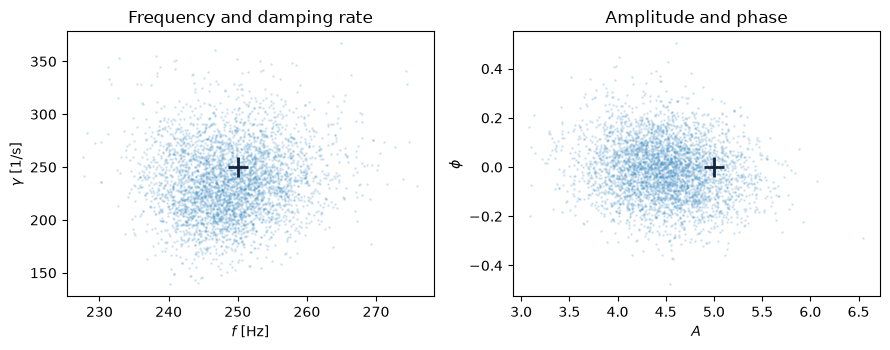

In [14]:
_theta = posterior.theta.theta
_f, _g = np.asarray(_theta.f[..., 0]).ravel(), np.asarray(_theta.gamma[..., 0]).ravel()
_A, _phi = np.asarray(posterior.extras["A"][..., 0]).ravel(), np.asarray(posterior.extras["phi"][..., 0]).ravel()

_fig, _axes = plt.subplots(1, 2, figsize=(9.0, 3.6))
_axes[0].plot(_f, _g, ".", color=POSTERIOR, alpha=0.15, markersize=2)
_axes[0].plot(float(truth.f[0]), float(truth.gamma[0]), "+", color=TRUTH, markersize=14, mew=2)
_axes[0].set(xlabel="$f$ [Hz]", ylabel=r"$\gamma$ [1/s]", title="Frequency and damping rate")
_axes[1].plot(_A, _phi, ".", color=POSTERIOR, alpha=0.15, markersize=2)
_axes[1].plot(float(truth.amplitude()[0]), float(truth.phase()[0]), "+", color=TRUTH,
              markersize=14, mew=2)
_axes[1].set(xlabel="$A$", ylabel=r"$\phi$", title="Amplitude and phase")
_fig.tight_layout()
_fig

The measurement process evaluates the signal for a batch of $\theta$ too. The reconstructed
waveforms of 1000 posterior draws, with their 90% band:

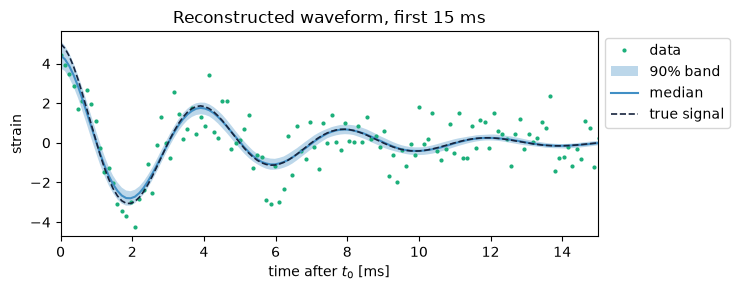

In [15]:
_theta = posterior.theta.theta
_draws = _theta.reshape_batch((int(np.prod(_theta.batch_shape)),))[:1000]
_h = np.asarray(jax.vmap(detector.signal)(_draws))
_lo, _mid, _hi = np.percentile(_h, [5, 50, 95], axis=0)
_t = 1e3 * np.asarray(detector.t)

_fig, _ax = plt.subplots(figsize=(7.5, 3.0))
_ax.plot(_t, np.asarray(data.h), ".", color=DATA, markersize=4, label="data")
_ax.fill_between(_t, _lo, _hi, color=POSTERIOR, alpha=0.35, linewidth=0, label="90% band")
_ax.plot(_t, _mid, color=POSTERIOR, linewidth=1.5, label="median")
_ax.plot(_t, np.asarray(detector.signal(truth)), color=TRUTH, linestyle="--", linewidth=1.2,
         label="true signal")
_ax.set(xlim=(0, 15), xlabel="time after $t_0$ [ms]", ylabel="strain",
        title="Reconstructed waveform, first 15 ms")
_ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
_fig.tight_layout()
_fig

Notebook 5 keeps the measurement process and the prior in this form but ties the frequencies
and damping rates of two modes to the mass and spin of a Kerr black hole, and observes them in
two detectors with coloured noise.